In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python working!")
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Python working!
NumPy: 2.4.6
Pandas: 3.0.2


In [2]:
from sklearn.ensemble import RandomForestClassifier

print("Scikit-learn is working!")

Scikit-learn is working!


In [4]:
import numpy as np
import pandas as pd

np.random.seed(42)

n = 5000

amount = np.random.exponential(100, n)
hour = np.random.randint(0, 24, n)
distance = np.random.exponential(20, n)
transactions = np.random.randint(1, 15, n)
international = np.random.randint(0, 2, n)

risk = (
    (amount > 400) * 0.25
    + (hour < 5) * 0.20
    + (distance > 80) * 0.20
    + (transactions > 10) * 0.20
    + international * 0.15
)

probability = np.clip(risk * 0.15, 0, 0.95)

fraud = (
    np.random.random(n) < probability
).astype(int)

df = pd.DataFrame({
    "Amount": amount,
    "Hour": hour,
    "Distance": distance,
    "Transactions": transactions,
    "International": international,
    "Class": fraud
})

print("Dataset created successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset created successfully!
Dataset shape: (5000, 6)


,Amount,Hour,Distance,Transactions,International,Class
0,46.926809,18,41.112172,1,1,0
1,301.012143,7,2.064098,4,1,0
2,131.674569,6,11.464712,2,0,0
3,91.294255,15,65.563486,14,1,0
4,16.962487,18,35.932063,14,1,0


In [5]:
print(df["Class"].value_counts())

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nFraud percentage:")
print(df["Class"].mean() * 100)

Class
0    4877
1     123
Name: count, dtype: int64

Missing values:
0

Fraud percentage:
2.46


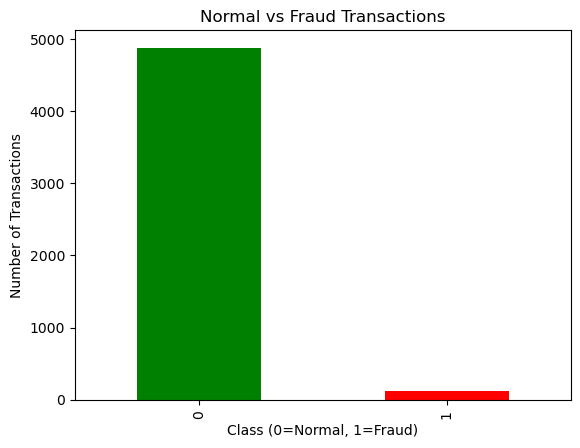

In [6]:
import matplotlib.pyplot as plt

df["Class"].value_counts().plot(
    kind="bar",
    color=["green", "red"]
)

plt.title("Normal vs Fraud Transactions")
plt.xlabel("Class (0=Normal, 1=Fraud)")
plt.ylabel("Number of Transactions")
plt.show()

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

X = df.drop("Class", axis=1)
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

model = RandomForestClassifier(
    n_estimators=50,
    max_depth=10,
    class_weight="balanced",
    random_state=42
)

model.fit(X_train, y_train)

print("Random Forest Model Trained Successfully!")

Random Forest Model Trained Successfully!


In [8]:
y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Predictions completed!")

print("Actual values:")
print(y_test.head(10).values)

print("\nPredicted values:")
print(y_pred[:10])

Predictions completed!
Actual values:
[0 0 0 0 0 0 0 0 0 0]

Predicted values:
[0 0 0 0 0 0 0 0 0 0]


In [9]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("FRAUD DETECTION MODEL PERFORMANCE")
print("----------------------------------")

print("Accuracy :", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall   :", round(recall * 100, 2), "%")
print("F1 Score :", round(f1 * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

FRAUD DETECTION MODEL PERFORMANCE
----------------------------------
Accuracy : 96.9 %
Precision: 0.0 %
Recall   : 0.0 %
F1 Score : 0.0 %

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       975
           1       0.00      0.00      0.00        25

    accuracy                           0.97      1000
   macro avg       0.49      0.50      0.49      1000
weighted avg       0.95      0.97      0.96      1000



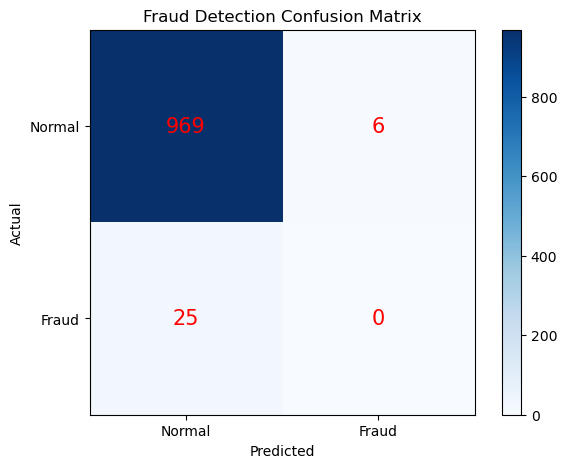

Confusion Matrix:
[[969   6]
 [ 25   0]]


In [11]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))

plt.imshow(cm, interpolation="nearest", cmap="Blues")

plt.title("Fraud Detection Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks([0, 1], ["Normal", "Fraud"])
plt.yticks([0, 1], ["Normal", "Fraud"])

# Display values inside matrix
for i in range(2):
    for j in range(2):
        plt.text(
            j, i,
            str(cm[i, j]),
            ha="center",
            va="center",
            color="red",
            fontsize=15
        )

plt.colorbar()
plt.show()

print("Confusion Matrix:")
print(cm)

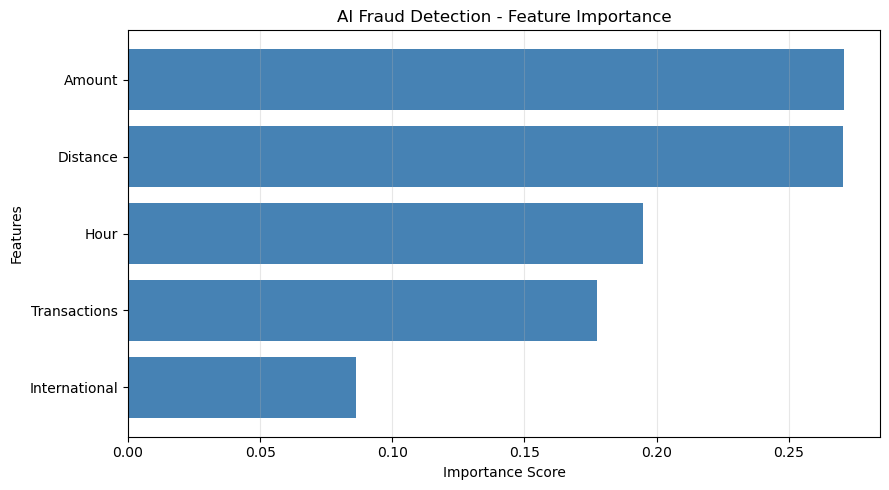

Top Important Features:


,Feature,Importance
0,Amount,0.271027
2,Distance,0.270454
1,Hour,0.194839
3,Transactions,0.177505
4,International,0.086175


In [17]:
import pandas as pd
import matplotlib.pyplot as plt

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(9, 5))

plt.barh(
    importance["Feature"],
    importance["Importance"],
    color="steelblue"
)

plt.title("AI Fraud Detection - Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Features")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

print("Top Important Features:")
display(importance.sort_values(
    by="Importance",
    ascending=False
))

In [18]:
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

Accuracy: 96.9 %
Precision: 0.0 %
Recall: 0.0 %
F1 Score: 0.0 %


In [14]:
new_transaction = pd.DataFrame([{
    "Amount": 5000,
    "Hour": 3,
    "Distance": 150,
    "Transactions": 12,
    "International": 1
}])

prediction = model.predict(new_transaction)[0]

fraud_probability = model.predict_proba(
    new_transaction
)[0][1]

print("TRANSACTION ANALYSIS")
print("----------------------")

print("Amount: 5000")
print("Fraud Risk Score:",
      round(fraud_probability * 100, 2), "%")

if prediction == 1:
    print("ALERT: Potential Fraud Detected!")
else:
    print("Transaction Classified as Normal")

TRANSACTION ANALYSIS
----------------------
Amount: 5000
Fraud Risk Score: 8.16 %
Transaction Classified as Normal


In [15]:
import joblib

joblib.dump(model, "fraud_detection_model.pkl")

print("Model saved successfully!")

Model saved successfully!


In [16]:
print("=" * 45)
print("AI-BASED FRAUD DETECTION SYSTEM")
print("=" * 45)

print("Algorithm: Random Forest")
print("Total Transactions:", len(df))
print("Fraud Transactions:", int(df["Class"].sum()))

print("-" * 45)

print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

print("-" * 45)
print("PROJECT COMPLETED SUCCESSFULLY!")

AI-BASED FRAUD DETECTION SYSTEM
Algorithm: Random Forest
Total Transactions: 5000
Fraud Transactions: 123
---------------------------------------------
Accuracy: 96.9 %
Precision: 0.0 %
Recall: 0.0 %
F1 Score: 0.0 %
---------------------------------------------
PROJECT COMPLETED SUCCESSFULLY!


In [19]:
print("Actual Fraud Cases:", sum(y_test))
print("Predicted Fraud Cases:", sum(y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Actual Fraud Cases: 25
Predicted Fraud Cases: 6

Confusion Matrix:
[[969   6]
 [ 25   0]]


In [20]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=150,
    max_depth=12,
    min_samples_leaf=2,
    class_weight="balanced_subsample",
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

y_probability = model.predict_proba(X_test)[:, 1]

print("Improved Model Training Completed!")

Improved Model Training Completed!


In [21]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("IMPROVED MODEL RESULTS")
print("----------------------")
print("Accuracy:", round(accuracy * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")
print("Recall:", round(recall * 100, 2), "%")
print("F1 Score:", round(f1 * 100, 2), "%")

IMPROVED MODEL RESULTS
----------------------
Accuracy: 97.3 %
Precision: 0.0 %
Recall: 0.0 %
F1 Score: 0.0 %
